In [1]:
import mne
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as mp
from glob import glob
from pathlib import Path
from scipy.ndimage import zoom
from PIL import Image
import os
import re
import torch.nn as nn
from sklearn.model_selection import train_test_split
import random
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import copy

In [100]:
base_dir=r"H:\Paper_1\Features\Amplitude_Based\AEC_Class\AEC"
def load_all_bands_per_subject(base_dir, bands_list, group_name, dtype=np.float32):
    subjects={}

    for band in bands_list:
        band_dir=os.path.join(base_dir, band, group_name)
        for fname in sorted(os.listdir(band_dir)):
            if not fname.endswith(".png"):
                continue

            #fname: subjX_winY.png
            name=fname[:-4]
            subj_part, _ =name.split("_")
            subj_id=int(subj_part[4:])

            img=np.asarray(Image.open(os.path.join(band_dir, fname)), dtype=dtype)

            #Initialize dict for subject if not exists
            if subj_id not in subjects:
                subjects[subj_id]={}
            #Append image to the correct band
            subjects[subj_id].setdefault(band, []).append(img)

    #Convert lists to arrays
    all_subjects=[]
    for subj_id in sorted(subjects):
        subj_dict={}
        for band in bands_list:
            subj_dict[band]=np.stack(subjects[subj_id][band])  #shape: (num_windows, H, W)
        all_subjects.append(subj_dict)

    return all_subjects

#Usage
bands_list=["alpha", "beta", "delta","gamma", "theta"]
scz_dfc=load_all_bands_per_subject(base_dir, bands_list, "SCZ")
hc_dfc=load_all_bands_per_subject(base_dir, bands_list, "HC")

#Example
print(scz_dfc[0]['alpha'].shape)  #(num_windows, H, W)

(621, 128, 128)


In [101]:
def normalize_subjects_minus1_to_1(subjects):
    """
    subjects: list of dicts
              subjects[i][band] -> (num_windows, H, W) uint8/float
    returns: normalized subjects (float32 in [-1,1])
    """
    for subj in subjects:
        for band in subj:
            x=subj[band].astype(np.float32)
            x=x / 255.0        #[0,1]
            x=x * 2.0 - 1.0    #[-1,1]
            subj[band] = x
    return subjects

scz_dfc=normalize_subjects_minus1_to_1(scz_dfc)
hc_dfc=normalize_subjects_minus1_to_1(hc_dfc)

print(scz_dfc[0]['alpha'].min(), scz_dfc[0]['alpha'].max())

-0.8352941 0.96862745


Single Band Model Pipeline

In [4]:
scz_alpha=[subj['alpha'] for subj in scz_dfc]
hc_alpha=[subj['alpha'] for subj in hc_dfc]

print(len(scz_alpha))  # number of SCZ subjects
print(scz_alpha[0].shape)

14
(621, 128, 128)


In [5]:
total_windows_scz = sum(subj.shape[0] for subj in scz_alpha)
print("Total SCZ windows:", total_windows_scz)

Total SCZ windows: 6237


In [9]:
# -------------------------------------------------
# 1️⃣ Subject labels
# -------------------------------------------------

scz_subjects = scz_alpha
hc_subjects  = hc_alpha

scz_labels = [1] * len(scz_subjects)
hc_labels  = [0] * len(hc_subjects)

all_subjects = scz_subjects + hc_subjects
all_labels   = scz_labels + hc_labels

# -------------------------------------------------
# 2️⃣ Subject-wise train-test split
# -------------------------------------------------

train_subjects, test_subjects, train_labels, test_labels = train_test_split(
    all_subjects,
    all_labels,
    test_size=0.2,
    stratify=all_labels,
    random_state=42
)

print("Train subjects:", len(train_subjects))
print("Test subjects:", len(test_subjects))

# -------------------------------------------------
# 3️⃣ Concatenate windows AFTER splitting
# -------------------------------------------------

def flatten_subjects(subject_list, label_list):
    X = []
    y = []

    for subj_data, label in zip(subject_list, label_list):
        X.append(subj_data)
        y.append(np.full(subj_data.shape[0], label))

    X = np.concatenate(X, axis=0)
    y = np.concatenate(y, axis=0)

    return X, y

X_train, y_train = flatten_subjects(train_subjects, train_labels)
X_test,  y_test  = flatten_subjects(test_subjects,  test_labels)

print("Train windows:", X_train.shape)
print("Test windows:", X_test.shape)

# -------------------------------------------------
# 4️⃣ Add channel dimension
# -------------------------------------------------

X_train = np.expand_dims(X_train, axis=1)
X_test  = np.expand_dims(X_test, axis=1)

# -------------------------------------------------
# 5️⃣ Dataset & DataLoader
# -------------------------------------------------

class AlphaDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = AlphaDataset(X_train, y_train)
test_dataset  = AlphaDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=32)

Train subjects: 22
Test subjects: 6
Train windows: (10692, 128, 128)
Test windows: (3132, 128, 128)


In [58]:
from torch.utils.data import DataLoader

# Example: train_dataset is your dataset object
labels = [label for _, label in train_dataset]  # list of all labels

N_pos = sum([1 for l in labels if l == 1])
N_neg = sum([1 for l in labels if l == 0])

print("Positives:", N_pos, "Negatives:", N_neg)
print(N_pos/N_neg)

Positives: 4617 Negatives: 6075
0.76


In [59]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.05),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            # Extra shallow refinement block (important!)
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )


        # Adaptive pooling removes dependency on input size
        self.global_pool = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.AdaptiveMaxPool2d((1,1)))
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),  # adjust H, W
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Dropout(0.4),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = self.features(x)
        x_avg = F.adaptive_avg_pool2d(x, (1,1))
        x_max = F.adaptive_max_pool2d(x, (1,1))
        x = x_avg + x_max
        x = self.classifier(x)
        return x

In [60]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleCNN().to(device)
pos_weight = torch.tensor([N_neg / N_pos]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-5)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=3, factor=0.5)

In [61]:
def train_model(model, train_loader, test_loader, epochs=50, patience=5):

    train_losses = []
    test_losses = []
    train_accs = []
    test_accs = []
    test_aucs = []

    best_auc = 0
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):

        # ===================== TRAIN =====================
        model.train()
        running_loss = 0

        all_train_labels = []
        all_train_probs = []

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device).float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            probs = torch.sigmoid(outputs)

            all_train_labels.extend(labels.cpu().numpy())
            all_train_probs.extend(probs.detach().cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        train_preds = (np.array(all_train_probs) > 0.5).astype(int)
        train_labels_np = np.array(all_train_labels).astype(int)

        train_acc = accuracy_score(train_labels_np, train_preds)
        train_accs.append(train_acc)

        # ===================== VALIDATION =====================
        model.eval()
        running_loss = 0

        all_test_labels = []
        all_test_probs = []

        with torch.no_grad():
            for images, labels in test_loader:
                images = images.to(device)
                labels = labels.to(device).float().unsqueeze(1)

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_loss += loss.item()

                probs = torch.sigmoid(outputs)

                all_test_labels.extend(labels.cpu().numpy())
                all_test_probs.extend(probs.cpu().numpy())

        test_loss = running_loss / len(test_loader)
        test_losses.append(test_loss)

        test_preds = (np.array(all_test_probs) > 0.5).astype(int)
        test_labels_np = np.array(all_test_labels).astype(int)

        test_acc = accuracy_score(test_labels_np, test_preds)
        test_precision = precision_score(test_labels_np, test_preds)
        test_recall = recall_score(test_labels_np, test_preds)
        test_f1 = f1_score(test_labels_np, test_preds)
        test_auc = roc_auc_score(test_labels_np, all_test_probs)

        test_accs.append(test_acc)
        test_aucs.append(test_auc)

        scheduler.step(test_auc)

        print(f"Epoch [{epoch+1}/{epochs}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Val   Loss: {test_loss:.4f} | Test Acc: {test_acc:.4f} | "
              f"Precision: {test_precision:.4f} | Recall: {test_recall:.4f} | "
              f"F1: {test_f1:.4f} | AUC: {test_auc:.4f}")
        print("-"*60)

        # ===================== EARLY STOPPING =====================
        if test_auc > best_auc:
            best_auc = test_auc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print("✅ Best model updated")
        else:
            patience_counter += 1
            print(f"⏳ EarlyStopping counter: {patience_counter}/{patience}")

        if patience_counter >= patience:
            print("🛑 Early stopping triggered!")
            break

    # Load best model
    model.load_state_dict(best_model_wts)
    print(f"\n🎯 Best Validation AUC: {best_auc:.4f}")

    # ===================== PLOTS =====================

    mp.figure()
    mp.plot(train_losses)
    mp.plot(test_losses)
    mp.title("Loss Curve")
    mp.xlabel("Epoch")
    mp.ylabel("Loss")
    mp.legend(["Train", "Validation"])
    mp.show()

    mp.figure()
    mp.plot(train_accs)
    mp.plot(test_accs)
    mp.title("Accuracy Curve")
    mp.xlabel("Epoch")
    mp.ylabel("Accuracy")
    mp.legend(["Train", "Validation"])
    mp.show()

    return model

Epoch [1/50]
Train Loss: 0.3985 | Train Acc: 0.8550
Val   Loss: 1.1115 | Test Acc: 0.6737 | Precision: 0.8814 | Recall: 0.4265 | F1: 0.5749 | AUC: 0.7709
------------------------------------------------------------
✅ Best model updated
Epoch [2/50]
Train Loss: 0.1941 | Train Acc: 0.9404
Val   Loss: 0.7030 | Test Acc: 0.7503 | Precision: 0.7447 | Recall: 0.7870 | F1: 0.7653 | AUC: 0.8425
------------------------------------------------------------
✅ Best model updated
Epoch [3/50]
Train Loss: 0.1355 | Train Acc: 0.9578
Val   Loss: 0.8705 | Test Acc: 0.7682 | Precision: 0.9348 | Recall: 0.5932 | F1: 0.7258 | AUC: 0.8907
------------------------------------------------------------
✅ Best model updated
Epoch [4/50]
Train Loss: 0.0976 | Train Acc: 0.9723
Val   Loss: 0.6065 | Test Acc: 0.7874 | Precision: 0.7359 | Recall: 0.9185 | F1: 0.8171 | AUC: 0.9054
------------------------------------------------------------
✅ Best model updated
Epoch [5/50]
Train Loss: 0.0817 | Train Acc: 0.9741
Val 

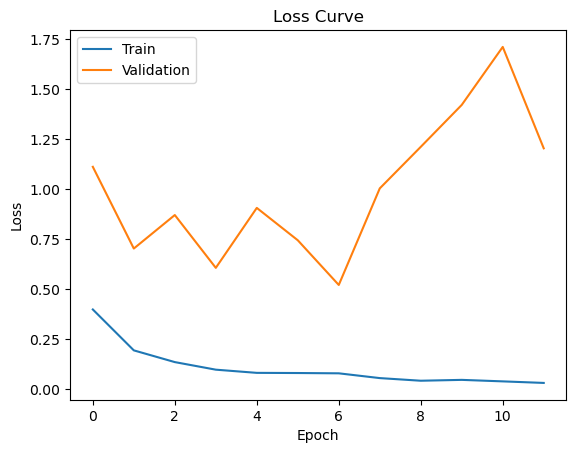

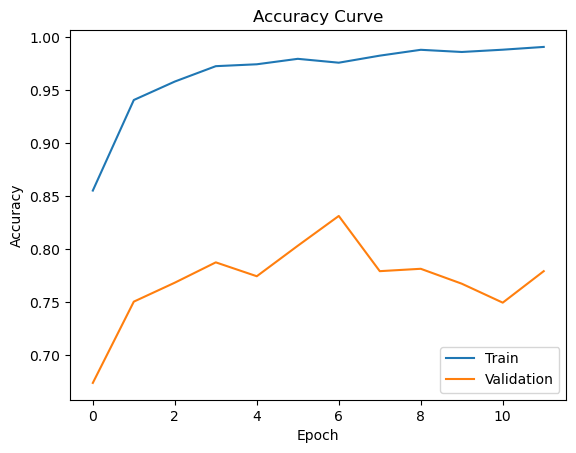

In [62]:
#train_model(model, train_loader, test_loader, epochs=100)
model=train_model(model, train_loader, test_loader, epochs=50, patience=5)

Multi Band Fusion Model Pipeline

In [102]:
bands_list = ["alpha", "beta", "delta", "gamma", "theta"]

def stack_bands(subjects, bands_list, label):
    all_windows = []
    all_labels = []
    all_subject_ids = []

    for subj_id, subj in enumerate(subjects):
        band_arrays = [subj[band] for band in bands_list]
        # each: (num_windows, H, W)

        stacked = np.stack(band_arrays, axis=1)
        # (num_windows, 5, 128, 128)

        num_windows = stacked.shape[0]

        all_windows.append(stacked)
        all_labels.append(np.full(num_windows, label))
        all_subject_ids.append(np.full(num_windows, subj_id))

    return (
        np.concatenate(all_windows, axis=0),
        np.concatenate(all_labels, axis=0),
        np.concatenate(all_subject_ids, axis=0),
    )

In [103]:
scz_X, scz_y, scz_subjects = stack_bands(scz_dfc, bands_list, label=1)
hc_X, hc_y, hc_subjects = stack_bands(hc_dfc, bands_list, label=0)

# Offset HC subject IDs
hc_subjects += scz_subjects.max() + 1

# Combine everything
X = np.concatenate([scz_X, hc_X], axis=0)
y = np.concatenate([scz_y, hc_y], axis=0)
subject_ids = np.concatenate([scz_subjects, hc_subjects], axis=0)

print("Total windows:", X.shape)
print("Total subjects:", len(np.unique(subject_ids)))

Total windows: (13824, 5, 128, 128)
Total subjects: 28


In [104]:
unique_subjects = np.unique(subject_ids)

train_subjects, test_subjects = train_test_split(unique_subjects, test_size=0.2, random_state=42)

train_mask = np.isin(subject_ids, train_subjects)
test_mask = np.isin(subject_ids, test_subjects)

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print("Train windows:", X_train.shape)
print("Test windows:", X_test.shape)

Train windows: (10881, 5, 128, 128)
Test windows: (2943, 5, 128, 128)


In [105]:
class MultiBandDataset(Dataset):
    def __init__(self, X, y, subject_ids):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).float()
        self.subject_ids = torch.from_numpy(subject_ids)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.subject_ids[idx]
        

train_dataset = MultiBandDataset(X_train, y_train, subject_ids[train_mask])
test_dataset = MultiBandDataset(X_test, y_test, subject_ids[test_mask])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

for images, labels, subjects in train_loader:
    print("Images:", images.shape)   # (32, 5, 128, 128)
    print("Labels:", labels.shape)   # (32,)
    print("Subjects:", subjects.shape)
    break

Images: torch.Size([32, 5, 128, 128])
Labels: torch.Size([32])
Subjects: torch.Size([32])


1. Shared CNN Architecture

In [10]:
class FusionCNN(nn.Module):
    def __init__(self, num_bands=5, input_size=128):
        super(FusionCNN, self).__init__()

        self.num_bands = num_bands

        # Shared CNN feature extractor
        self.band_cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 128 -> 64

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 64 -> 32

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)    # 32 -> 16
        )

        # Compute feature dimension dynamically
        dummy = torch.zeros(1, 1, input_size, input_size)
        dummy_out = self.band_cnn(dummy)
        self.feature_dim = dummy_out.numel()

        # Fusion classifier
        self.classifier = nn.Sequential(
            nn.Linear(self.feature_dim * num_bands, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        # x: (B, num_bands, 128, 128)

        band_features = []

        for i in range(self.num_bands):
            band = x[:, i:i+1, :, :]        # (B,1,H,W)
            feat = self.band_cnn(band)      # (B,128,16,16)
            feat = feat.flatten(1)          # safer than view
            band_features.append(feat)

        fused = torch.cat(band_features, dim=1)
        out = self.classifier(fused)

        return out.squeeze(1)  # (B,)

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FusionCNN().to(device) 
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [16]:
from collections import defaultdict

def train_model(model, train_loader, test_loader, epochs=50, patience=5):

    train_losses = []
    test_losses = []
    train_accs = []
    test_accs = []
    test_aucs = []

    best_auc = 0
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):

        # ===================== TRAIN =====================
        model.train()
        running_loss = 0

        all_train_labels = []
        all_train_probs = []

        for images, labels, _ in train_loader:

            images = images.to(device)
            labels = labels.to(device).float()

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            probs = torch.sigmoid(outputs)

            all_train_labels.extend(labels.cpu().numpy())
            all_train_probs.extend(probs.detach().cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        train_preds = (np.array(all_train_probs) > 0.5).astype(int)
        train_labels_np = np.array(all_train_labels).astype(int)

        train_acc = accuracy_score(train_labels_np, train_preds)
        train_accs.append(train_acc)

        # ===================== VALIDATION =====================
        model.eval()
        running_loss = 0

        all_test_labels = []
        all_test_probs = []
        all_test_subjects = []

        with torch.no_grad():
            for images, labels, subjects in test_loader:

                images = images.to(device)
                labels = labels.to(device).float()

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_loss += loss.item()

                probs = torch.sigmoid(outputs)

                all_test_labels.extend(labels.cpu().numpy())
                all_test_probs.extend(probs.cpu().numpy())
                all_test_subjects.extend(subjects.cpu().numpy())

        test_loss = running_loss / len(test_loader)
        test_losses.append(test_loss)

        # ===================== WINDOW-LEVEL METRICS =====================
        test_preds = (np.array(all_test_probs) > 0.5).astype(int)
        test_labels_np = np.array(all_test_labels).astype(int)

        test_acc = accuracy_score(test_labels_np, test_preds)
        test_auc = roc_auc_score(test_labels_np, all_test_probs)

        # ===================== SUBJECT-LEVEL METRICS =====================
        subject_probs = defaultdict(list)
        subject_labels = {}

        for prob, label, subj in zip(all_test_probs, all_test_labels, all_test_subjects):
            subject_probs[subj].append(prob)
            subject_labels[subj] = label  # same for all windows

        subj_avg_probs = []
        subj_true_labels = []

        for subj in subject_probs:
            avg_prob = np.mean(subject_probs[subj])
            subj_avg_probs.append(avg_prob)
            subj_true_labels.append(subject_labels[subj])

        subj_preds = (np.array(subj_avg_probs) > 0.5).astype(int)

        subj_acc = accuracy_score(subj_true_labels, subj_preds)
        subj_precision = precision_score(subj_true_labels, subj_preds)
        subj_recall = recall_score(subj_true_labels, subj_preds)
        subj_f1 = f1_score(subj_true_labels, subj_preds)
        subj_auc = roc_auc_score(subj_true_labels, subj_avg_probs)

        test_accs.append(test_acc)
        test_aucs.append(test_auc)

        print(f"\nEpoch [{epoch+1}/{epochs}]")
        print("---- Window-Level ----")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.4f} | AUC: {test_auc:.4f}")

        print("---- Subject-Level ----")
        print(f"Acc: {subj_acc:.4f} | Precision: {subj_precision:.4f} | "
              f"Recall: {subj_recall:.4f} | F1: {subj_f1:.4f} | "
              f"AUC: {subj_auc:.4f}")
        print("-"*60)

        # ===================== EARLY STOPPING (Subject AUC) =====================
        if subj_auc > best_auc:
            best_auc = subj_auc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print("Best model updated (based on Subject AUC)")
        else:
            patience_counter += 1
            print(f"EarlyStopping counter: {patience_counter}/{patience}")

        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

    model.load_state_dict(best_model_wts)
    print(f"\nBest Subject-Level Validation AUC: {best_auc:.4f}")

    return model

In [17]:
#train_model(model, train_loader, test_loader, epochs=100)
model=train_model(model, train_loader, test_loader, epochs=50, patience=5)


Epoch [1/50]
---- Window-Level ----
Train Loss: 0.1764 | Train Acc: 0.9235 | Val Loss: 0.4294 | Test Acc: 0.8736 | AUC: 0.9443
---- Subject-Level ----
Acc: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | AUC: 1.0000
------------------------------------------------------------
Best model updated (based on Subject AUC)

Epoch [2/50]
---- Window-Level ----
Train Loss: 0.0777 | Train Acc: 0.9583 | Val Loss: 0.9785 | Test Acc: 0.8457 | AUC: 0.9470
---- Subject-Level ----
Acc: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | AUC: 1.0000
------------------------------------------------------------
EarlyStopping counter: 1/5

Epoch [3/50]
---- Window-Level ----
Train Loss: 0.0655 | Train Acc: 0.9648 | Val Loss: 1.6570 | Test Acc: 0.7666 | AUC: 0.9414
---- Subject-Level ----
Acc: 0.8333 | Precision: 1.0000 | Recall: 0.7500 | F1: 0.8571 | AUC: 1.0000
------------------------------------------------------------
EarlyStopping counter: 2/5

Epoch [4/50]
---- Window-Level ----


2. Independent CNN Architecture

In [106]:
class BandCNN(nn.Module):
    def __init__(self):
        super(BandCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 128 -> 64

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 64 -> 32

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)    # 32 -> 16
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)  # (B, 128*16*16)
        return x


class FusionCNN(nn.Module):
    def __init__(self, num_bands=5, input_size=128, hidden_dims=(256,), dropout=0.5):
        """
        Classifier-head depth/width is controlled entirely by hidden_dims:

            hidden_dims=(256,)      -> baseline (original architecture):
                                        Linear -> 256 -> ReLU -> Dropout -> Linear -> 1
            hidden_dims=()          -> "linear" ablation condition (no hidden layer):
                                        Linear -> 1, straight from the fused features
            hidden_dims=(256, 128)  -> "deep" ablation condition (two hidden layers):
                                        Linear -> 256 -> ReLU -> Dropout -> 128 -> ReLU -> Dropout -> Linear -> 1
            hidden_dims=(512,)      -> optional "wide" condition, if you want width tested
                                        independently of depth

        dropout is applied after every hidden layer; it has no effect when
        hidden_dims=() since there is nothing to regularize before the output.
        """
        super(FusionCNN, self).__init__()
        self.num_bands = num_bands

        # 🔵 Independent CNN per band — unchanged, not part of this ablation
        self.band_cnns = nn.ModuleList([
            BandCNN() for _ in range(num_bands)
        ])

        # Compute feature dimension dynamically
        dummy = torch.zeros(1, 1, input_size, input_size)
        dummy_out = self.band_cnns[0](dummy)
        self.feature_dim = dummy_out.shape[1]

        # 🔵 Fusion classifier (late feature fusion) — depth/width configurable here
        in_dim = self.feature_dim * num_bands
        layers = []
        for h in hidden_dims:
            layers.append(nn.Linear(in_dim, h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.classifier = nn.Sequential(*layers)

    def forward(self, x):
        # x: (B, num_bands, H, W)

        band_features = []

        for i in range(self.num_bands):
            band = x[:, i:i+1, :, :]            # (B,1,H,W)
            feat = self.band_cnns[i](band)     # independent CNN
            band_features.append(feat)

        fused = torch.cat(band_features, dim=1)
        out = self.classifier(fused)

        return out.squeeze(1)  # (B,)

In [107]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FusionCNN().to(device) 
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [108]:
def train_model(model, train_loader, val_loader, epochs=50, patience=5):

    model.to(device)

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []
    val_aucs = []

    best_auc = 0.0
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):

        # ===================== TRAIN =====================
        model.train()
        running_loss = 0.0

        all_train_labels = []
        all_train_probs = []

        for images, labels, subjects in train_loader:

            
            images = images.to(device)
            labels = labels.to(device).float()

            optimizer.zero_grad()

            outputs = model(images)                     # (B,)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            probs = torch.sigmoid(outputs)

            all_train_labels.extend(labels.cpu().numpy())
            all_train_probs.extend(probs.detach().cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        train_preds = (np.array(all_train_probs) > 0.5).astype(int)
        train_labels_np = np.array(all_train_labels).astype(int)

        train_acc = accuracy_score(train_labels_np, train_preds)
        train_accs.append(train_acc)

        # ===================== VALIDATION =====================
        model.eval()
        running_loss = 0.0

        all_val_labels = []
        all_val_probs = []

        with torch.no_grad():
            
            for images, labels, subjects in val_loader:
            
                images = images.to(device)
                labels = labels.to(device).float()

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_loss += loss.item()

                probs = torch.sigmoid(outputs)

                all_val_labels.extend(labels.cpu().numpy())
                all_val_probs.extend(probs.cpu().numpy())

        val_loss = running_loss / len(val_loader)
        val_losses.append(val_loss)

        val_preds = (np.array(all_val_probs) > 0.5).astype(int)
        val_labels_np = np.array(all_val_labels).astype(int)

        val_acc = accuracy_score(val_labels_np, val_preds)
        val_precision = precision_score(val_labels_np, val_preds, zero_division=0)
        val_recall = recall_score(val_labels_np, val_preds, zero_division=0)
        val_f1 = f1_score(val_labels_np, val_preds, zero_division=0)

        try:
            val_auc = roc_auc_score(val_labels_np, all_val_probs)
        except ValueError:
            val_auc = 0.0  # Happens if only one class present

        val_accs.append(val_acc)
        val_aucs.append(val_auc)

        # ===================== LOGGING =====================
        print(f"Epoch [{epoch+1}/{epochs}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Test   Loss: {val_loss:.4f} | Test Acc: {val_acc:.4f} | "
              f"Precision: {val_precision:.4f} | Recall: {val_recall:.4f} | "
              f"F1: {val_f1:.4f} | AUC: {val_auc:.4f}")
        print("-" * 60)

        # ===================== EARLY STOPPING (AUC-based) =====================
        if val_auc > best_auc:
            best_auc = val_auc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print("Best model updated\n")
        else:
            patience_counter += 1
            print(f"EarlyStopping counter: {patience_counter}/{patience}\n")

        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

    model.load_state_dict(best_model_wts)
    print(f"\nBest Validation AUC: {best_auc:.4f}")

    return model

In [109]:
# =========================================================
# UPDATE 1: YOUDEN J THRESHOLD CALIBRATION
# Add AFTER train_model()
# =========================================================

from sklearn.metrics import roc_curve

def find_best_threshold_youden(y_true, probs):


    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs)

    fpr, tpr, thresholds = roc_curve(y_true, probs)

    # Youden's J
    j_scores = tpr - fpr

    # Remove non-finite thresholds
    valid = np.isfinite(thresholds)

    fpr = fpr[valid]
    tpr = tpr[valid]
    thresholds = thresholds[valid]
    j_scores = j_scores[valid]

    # Threshold giving maximum Youden J
    best_idx = np.argmax(j_scores)

    best_threshold = thresholds[best_idx]
    best_j = j_scores[best_idx]

    best_sensitivity = tpr[best_idx]
    best_specificity = 1.0 - fpr[best_idx]

    return (best_threshold, best_j, best_sensitivity, best_specificity)

In [110]:
# =========================================================
# UPDATE 2: HELPER FUNCTIONS
# Add AFTER find_best_threshold_youden()
# =========================================================

def get_predictions(model, loader):

    model.eval()

    all_labels = []
    all_probs = []
    all_subjects = []

    with torch.no_grad():

        for images, labels, subjects in loader:

            images = images.to(device)

            outputs = model(images)

            probs = torch.sigmoid(outputs)

            all_labels.extend(labels.cpu().numpy())

            all_probs.extend(probs.cpu().numpy())

            all_subjects.extend(subjects.cpu().numpy())

    return (
        np.array(all_labels).astype(int),
        np.array(all_probs),
        np.array(all_subjects)
    )


def aggregate_to_subjects(probs, labels, subjects):

    subject_probs = defaultdict(list)
    subject_labels = {}

    for prob, label, subj in zip(probs, labels, subjects):

        subject_probs[subj].append(float(prob))

        subject_labels[subj] = int(label)

    subj_ids = sorted(subject_probs.keys())

    subj_probs = np.array([np.mean(subject_probs[subj]) for subj in subj_ids])

    subj_labels = np.array([subject_labels[subj] for subj in subj_ids])

    return (subj_probs, subj_labels, np.array(subj_ids))

In [29]:
#train_model(model, train_loader, test_loader, epochs=100)
model=train_model(model, train_loader, test_loader, epochs=50, patience=5)

Epoch [1/50]
Train Loss: 1.3328 | Train Acc: 0.9265
Test   Loss: 1.5233 | Test Acc: 0.6303 | Precision: 0.9539 | Recall: 0.4281 | F1: 0.5910 | AUC: 0.8888
------------------------------------------------------------
Best model updated

Epoch [2/50]
Train Loss: 0.0872 | Train Acc: 0.9619
Test   Loss: 0.7342 | Test Acc: 0.7791 | Precision: 0.9662 | Recall: 0.6694 | F1: 0.7909 | AUC: 0.9292
------------------------------------------------------------
Best model updated

Epoch [3/50]
Train Loss: 0.0806 | Train Acc: 0.9666
Test   Loss: 0.7885 | Test Acc: 0.8420 | Precision: 0.9957 | Recall: 0.7500 | F1: 0.8555 | AUC: 0.9747
------------------------------------------------------------
Best model updated

Epoch [4/50]
Train Loss: 0.0443 | Train Acc: 0.9790
Test   Loss: 0.4938 | Test Acc: 0.8036 | Precision: 0.9715 | Recall: 0.7059 | F1: 0.8177 | AUC: 0.9565
------------------------------------------------------------
EarlyStopping counter: 1/5

Epoch [5/50]
Train Loss: 0.0561 | Train Acc: 0.9

2.1 5-fold cross validation

In [111]:
from sklearn.model_selection import StratifiedKFold

# Get unique subjects
unique_subjects = np.unique(subject_ids)

# Create subject-level labels
subject_to_label = {}

for subj in unique_subjects:
    # all windows from this subject have same label
    subj_label = y[subject_ids == subj][0]
    subject_to_label[subj] = subj_label

subject_labels = np.array([subject_to_label[s] for s in unique_subjects])

In [112]:
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

In [113]:
from collections import defaultdict

fold_results = []

for fold, (trainval_subj_idx, test_subj_idx) in enumerate(
        skf.split(unique_subjects, subject_labels)):
    print(f"\n========== Fold {fold+1}/{n_splits} ==========")

    trainval_subjects = unique_subjects[trainval_subj_idx]
    test_subjects      = unique_subjects[test_subj_idx]        # touched once, at final eval only
    trainval_labels    = subject_labels[trainval_subj_idx]     # for stratifying the inner split

    # ---- Inner split: carve a validation set out of the TRAINING pool only ----
    inner_train_subjects, inner_val_subjects = train_test_split(
        trainval_subjects,
        test_size=0.2,
        stratify=trainval_labels,
        random_state=42
    )

    inner_train_mask = np.isin(subject_ids, inner_train_subjects)
    inner_val_mask   = np.isin(subject_ids, inner_val_subjects)
    test_mask        = np.isin(subject_ids, test_subjects)

    X_train, y_train = X[inner_train_mask], y[inner_train_mask]
    X_val,   y_val   = X[inner_val_mask],   y[inner_val_mask]
    X_test,  y_test  = X[test_mask],        y[test_mask]

    train_dataset = MultiBandDataset(X_train, y_train, subject_ids[inner_train_mask])
    val_dataset   = MultiBandDataset(X_val,   y_val,   subject_ids[inner_val_mask])
    test_dataset  = MultiBandDataset(X_test,  y_test,  subject_ids[test_mask])

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)   # used ONLY for early stopping
    test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)   # used ONLY for final metrics

    print(f"Inner train subjects: {len(inner_train_subjects)} | "
          f"Inner val subjects: {len(inner_val_subjects)} | "
          f"Test subjects: {len(test_subjects)}")

    model = FusionCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    # train_model() itself needs no changes — it already treats its second
    # loader argument as the early-stopping signal. The fix is that we now
    # pass it the INNER val_loader, not the outer test fold.
    trained_model = train_model(model, train_loader, val_loader, epochs=50, patience=5)

    #########################################################
    # Final evaluation on this fold
    #########################################################
    
    #########################################################
    # VALIDATION PREDICTIONS
    #########################################################
    
    # Use the INNER VALIDATION SET only to calibrate the decision threshold.
    
    val_labels, val_probs, val_subjects_arr = get_predictions(trained_model, val_loader)
    
    
    #########################################################
    # VALIDATION: WINDOW -> SUBJECT
    #########################################################
    
    val_subj_probs, val_subj_labels, val_subj_ids = \
        aggregate_to_subjects(val_probs, val_labels, val_subjects_arr)
    
    
    #########################################################
    # YOUDEN J THRESHOLD CALIBRATION
    #########################################################
    
    (best_threshold, best_j, val_sensitivity, val_specificity) = find_best_threshold_youden(val_subj_labels, val_subj_probs)
    
    
    print("\n" + "-" * 60)
    print("THRESHOLD CALIBRATION")
    print(f"Youden J threshold : "
        f"{best_threshold:.4f}")
    print(f"Youden J           : "
        f"{best_j:.4f}")
    print(f"Validation Sens.   : "
        f"{val_sensitivity:.4f}")
    print(f"Validation Spec.   : "
        f"{val_specificity:.4f}")
    
    
    #########################################################
    # FINAL EVALUATION ON OUTER TEST FOLD
    #########################################################
    
    
    test_labels, test_probs, test_subjects_arr = get_predictions(trained_model, test_loader)
    
    
    #########################################################
    # WINDOW LEVEL
    #########################################################
    
    # Apply validation-derived Youden threshold
    test_preds = (test_probs >= best_threshold).astype(int)
    win_acc = accuracy_score(test_labels, test_preds)
    win_prec = precision_score(test_labels, test_preds, zero_division=0)
    win_rec = recall_score(test_labels, test_preds, zero_division=0)
    win_f1 = f1_score(test_labels, test_preds, zero_division=0)
    
    try:
    
        win_auc = roc_auc_score(test_labels, test_probs)
    
    except ValueError:
    
        win_auc = np.nan
    
    # Window-level confusion matrix
    tn, fp, fn, tp = confusion_matrix(test_labels, test_preds, labels=[0, 1]).ravel()
    
    win_spec = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )
    
    
    #########################################################
    # SUBJECT LEVEL
    #########################################################
    
    # Aggregate TEST windows -> TEST subjects
    
    subj_probs, subj_labels, subj_ids = \
        aggregate_to_subjects(
            test_probs,
            test_labels,
            test_subjects_arr
        )
    
    
    subj_preds = (subj_probs >= best_threshold).astype(int)
    subj_acc = accuracy_score(subj_labels, subj_preds)
    subj_prec = precision_score(subj_labels, subj_preds, zero_division=0)
    subj_rec = recall_score(subj_labels, subj_preds, zero_division=0)
    subj_f1 = f1_score(subj_labels, subj_preds, zero_division=0)
    
    try:
    
        subj_auc = roc_auc_score(subj_labels, subj_probs)
    
    except ValueError:
    
        subj_auc = np.nan
    
    
    #########################################################
    # SUBJECT-LEVEL CONFUSION MATRIX
    #########################################################
    
    subj_tn, subj_fp, subj_fn, subj_tp = confusion_matrix(subj_labels, subj_preds, labels=[0, 1]).ravel()
    
    subj_spec = (
        subj_tn / (subj_tn + subj_fp)
        if (subj_tn + subj_fp) > 0
        else 0.0
    )
    
    
    #########################################################
    # SAVE FOLD RESULTS
    #########################################################
    
    fold_results.append({
    
        # ---------------------------------------------
        # Threshold calibration
        # ---------------------------------------------
    
        "threshold":
            best_threshold,
    
        "youden_j":
            best_j,
    
        "val_sensitivity":
            val_sensitivity,
    
        "val_specificity":
            val_specificity,
    
    
        # ---------------------------------------------
        # Window-level metrics
        # ---------------------------------------------
    
        "win_acc":
            win_acc,
    
        "win_auc":
            win_auc,
    
        "win_precision":
            win_prec,
    
        "win_recall":
            win_rec,
    
        "win_specificity":
            win_spec,
    
        "win_f1":
            win_f1,
    
    
        # Window confusion matrix
        "win_tn":
            tn,
    
        "win_fp":
            fp,
    
        "win_fn":
            fn,
    
        "win_tp":
            tp,
    
    
        # ---------------------------------------------
        # Subject-level metrics
        # ---------------------------------------------
    
        "subj_acc":
            subj_acc,
    
        "subj_auc":
            subj_auc,
    
        "subj_precision":
            subj_prec,
    
        "subj_recall":
            subj_rec,
    
        "subj_specificity":
            subj_spec,
    
        "subj_f1":
            subj_f1,
    
    
        # Subject confusion matrix
        "subj_tn":
            subj_tn,
    
        "subj_fp":
            subj_fp,
    
        "subj_fn":
            subj_fn,
    
        "subj_tp":
            subj_tp
    })
    
    
    #########################################################
    # PRINT FOLD RESULTS
    #########################################################
    
    print("\nFold {} Results".format(fold + 1))
    
    print(
        f"Calibrated Threshold: "
        f"{best_threshold:.4f}"
    )
    
    print(
        f"Youden J: "
        f"{best_j:.4f}"
    )
    
    
    print(
        "\nWindow -> "
        f"Acc: {win_acc:.4f} | "
        f"AUC: {win_auc:.4f} | "
        f"Prec: {win_prec:.4f} | "
        f"Rec: {win_rec:.4f} | "
        f"Spec: {win_spec:.4f} | "
        f"F1: {win_f1:.4f}"
    )
    
    print(
        f"Window Confusion Matrix: "
        f"TN={tn}, FP={fp}, FN={fn}, TP={tp}"
    )
    
    
    print(
        "\nSubject -> "
        f"Acc: {subj_acc:.4f} | "
        f"AUC: {subj_auc:.4f} | "
        f"Prec: {subj_prec:.4f} | "
        f"Rec: {subj_rec:.4f} | "
        f"Spec: {subj_spec:.4f} | "
        f"F1: {subj_f1:.4f}"
    )
    
    print(
        f"Subject Confusion Matrix: "
        f"TN={subj_tn}, FP={subj_fp}, "
        f"FN={subj_fn}, TP={subj_tp}"
    )


#########################################################
# Average Results Across All Folds
#########################################################

print("\n" + "=" * 70)
print("AVERAGE CROSS-VALIDATION RESULTS")
print("=" * 70)


#########################################################
# THRESHOLD
#########################################################

print("\nThreshold Calibration")
print(f"Youden Threshold: "
    f"{np.mean([x['threshold'] for x in fold_results]):.4f} ± "
    f"{np.std([x['threshold'] for x in fold_results]):.4f}")

print(f"Youden J: "
    f"{np.mean([x['youden_j'] for x in fold_results]):.4f} ± "
    f"{np.std([x['youden_j'] for x in fold_results]):.4f}")


#########################################################
# WINDOW LEVEL
#########################################################

print("\nWindow-Level Performance")
print(f"Accuracy    : "
    f"{np.mean([x['win_acc'] for x in fold_results]):.4f} ± "
    f"{np.std([x['win_acc'] for x in fold_results]):.4f}")
print(f"AUC         : "
    f"{np.mean([x['win_auc'] for x in fold_results]):.4f} ± "
    f"{np.std([x['win_auc'] for x in fold_results]):.4f}")
print(f"Precision   : "
    f"{np.mean([x['win_precision'] for x in fold_results]):.4f} ± "
    f"{np.std([x['win_precision'] for x in fold_results]):.4f}")
print(f"Recall      : "
    f"{np.mean([x['win_recall'] for x in fold_results]):.4f} ± "
    f"{np.std([x['win_recall'] for x in fold_results]):.4f}")
print(f"Specificity : "
    f"{np.mean([x['win_specificity'] for x in fold_results]):.4f} ± "
    f"{np.std([x['win_specificity'] for x in fold_results]):.4f}")
print(f"F1-score    : "
    f"{np.mean([x['win_f1'] for x in fold_results]):.4f} ± "
    f"{np.std([x['win_f1'] for x in fold_results]):.4f}")

#########################################################
# SUBJECT LEVEL
#########################################################

print("\nSubject-Level Performance")
print(f"Accuracy    : "
    f"{np.mean([x['subj_acc'] for x in fold_results]):.4f} ± "
    f"{np.std([x['subj_acc'] for x in fold_results]):.4f}")
print(f"AUC         : "
    f"{np.mean([x['subj_auc'] for x in fold_results]):.4f} ± "
    f"{np.std([x['subj_auc'] for x in fold_results]):.4f}")
print(f"Precision   : "
    f"{np.mean([x['subj_precision'] for x in fold_results]):.4f} ± "
    f"{np.std([x['subj_precision'] for x in fold_results]):.4f}")
print(f"Recall      : "
    f"{np.mean([x['subj_recall'] for x in fold_results]):.4f} ± "
    f"{np.std([x['subj_recall'] for x in fold_results]):.4f}")
print(f"Specificity : "
    f"{np.mean([x['subj_specificity'] for x in fold_results]):.4f} ± "
    f"{np.std([x['subj_specificity'] for x in fold_results]):.4f}")
print(f"F1-score    : "
    f"{np.mean([x['subj_f1'] for x in fold_results]):.4f} ± "
    f"{np.std([x['subj_f1'] for x in fold_results]):.4f}")


#########################################################
# FOLD-WISE SUBJECT-LEVEL CONFUSION MATRICES
#########################################################

print("\n" + "=" * 70)
print("FOLD-WISE SUBJECT-LEVEL CONFUSION MATRICES")
print("=" * 70)

for fold, result in enumerate(fold_results, start=1):

    print(f"\nFold {fold}:")
    print(f"Threshold = " f"{result['threshold']:.4f}")
    print(
        f"TN = {result['subj_tn']} | "
        f"FP = {result['subj_fp']} | "
        f"FN = {result['subj_fn']} | "
        f"TP = {result['subj_tp']}")


#########################################################
# POOLED SUBJECT-LEVEL CONFUSION MATRIX
#########################################################

total_subj_tn = sum(x["subj_tn"] for x in fold_results)
total_subj_fp = sum(x["subj_fp"] for x in fold_results)
total_subj_fn = sum(x["subj_fn"] for x in fold_results)
total_subj_tp = sum(x["subj_tp"] for x in fold_results)

print("\n" + "=" * 70)
print("POOLED SUBJECT-LEVEL CONFUSION MATRIX")
print("=" * 70)
print(f"TN = {total_subj_tn}")
print(f"FP = {total_subj_fp}")
print(f"FN = {total_subj_fn}")
print(f"TP = {total_subj_tp}")
print("\nMatrix:")
print(f"[[{total_subj_tn}, {total_subj_fp}],")
print(f" [{total_subj_fn}, {total_subj_tp}]]")


========== Fold 1/5 ==========
Inner train subjects: 17 | Inner val subjects: 5 | Test subjects: 6
Epoch [1/50]
Train Loss: 1.5168 | Train Acc: 0.7531
Test   Loss: 0.5749 | Test Acc: 0.7508 | Precision: 0.8824 | Recall: 0.3758 | F1: 0.5271 | AUC: 0.8445
------------------------------------------------------------
Best model updated

Epoch [2/50]
Train Loss: 0.3118 | Train Acc: 0.8635
Test   Loss: 0.8667 | Test Acc: 0.7528 | Precision: 0.8248 | Recall: 0.4205 | F1: 0.5570 | AUC: 0.8131
------------------------------------------------------------
EarlyStopping counter: 1/5

Epoch [3/50]
Train Loss: 0.2657 | Train Acc: 0.8808
Test   Loss: 0.6126 | Test Acc: 0.7903 | Precision: 0.9043 | Recall: 0.4837 | F1: 0.6302 | AUC: 0.8825
------------------------------------------------------------
Best model updated

Epoch [4/50]
Train Loss: 0.2561 | Train Acc: 0.8876
Test   Loss: 0.4352 | Test Acc: 0.8305 | Precision: 0.9041 | Recall: 0.6057 | F1: 0.7254 | AUC: 0.9063
-----------------------------

In [114]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

unique_subjects = np.unique(subject_ids)

subject_to_label = {
    int(sid): int(y[np.where(subject_ids == sid)[0][0]])
    for sid in unique_subjects
}
subject_labels = np.array([subject_to_label[int(s)] for s in unique_subjects])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for fold, (train_idx, test_idx) in enumerate(
    skf.split(unique_subjects, subject_labels), start=1
):
    trainval_subjects = unique_subjects[train_idx]
    test_subjects = unique_subjects[test_idx]
    trainval_labels = subject_labels[train_idx]

    inner_train_subjects, inner_val_subjects = train_test_split(
        trainval_subjects,
        test_size=0.2,
        stratify=trainval_labels,
        random_state=42
    )

    val_mask = np.isin(subject_ids, inner_val_subjects)

    rows.append({
        "Fold": fold,
        "Validation subjects (SCZ/HC)": (
            f"{sum(subject_to_label[int(s)] == 1 for s in inner_val_subjects)}/"
            f"{sum(subject_to_label[int(s)] == 0 for s in inner_val_subjects)}"
        ),
        "Validation windows (SCZ/HC)": (
            f"{int(np.sum(val_mask & (y == 1)))}/"
            f"{int(np.sum(val_mask & (y == 0)))}"
        )
    })

table_s7_counts = pd.DataFrame(rows)
print(table_s7_counts.to_string(index=False))
table_s7_counts.to_csv("Supplementary_Table_S7_counts.csv", index=False)

 Fold Validation subjects (SCZ/HC) Validation windows (SCZ/HC)
    1                          2/3                    918/1566
    2                          2/3                    783/1539
    3                          2/3                    702/1674
    4                          2/3                    891/1566
    5                          3/2                   1080/1080


In [115]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

# ------------------------------------------------------
# 1. Reconstruct the subject-level labels
# ------------------------------------------------------
unique_subjects = np.unique(subject_ids)

subject_to_label = {}
for sid in unique_subjects:
    labels_this_subject = np.unique(y[subject_ids == sid])

    # Every window from one subject should have the same label
    assert len(labels_this_subject) == 1, (
        f"Subject {sid} has inconsistent labels!"
    )

    subject_to_label[int(sid)] = int(labels_this_subject[0])

subject_labels = np.array(
    [subject_to_label[int(sid)] for sid in unique_subjects]
)

print("Total subjects:", len(unique_subjects))
print("Total SCZ subjects:", int(np.sum(subject_labels == 1)))
print("Total HC subjects:", int(np.sum(subject_labels == 0)))

# ------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------
def count_subject_classes(subject_list):
    labels = np.array([
        subject_to_label[int(sid)] for sid in subject_list
    ])

    return (
        int(np.sum(labels == 1)),  # SCZ
        int(np.sum(labels == 0))   # HC
    )


def count_window_classes(mask):
    return (
        int(np.sum(mask & (y == 1))),  # SCZ windows
        int(np.sum(mask & (y == 0)))   # HC windows
    )


# ------------------------------------------------------
# 3. Reproduce the exact outer and inner splits
# ------------------------------------------------------
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rows = []

for fold, (train_idx, test_idx) in enumerate(
    skf.split(unique_subjects, subject_labels),
    start=1
):
    trainval_subjects = unique_subjects[train_idx]
    test_subjects = unique_subjects[test_idx]
    trainval_labels = subject_labels[train_idx]

    # Match the inner split in your original code
    inner_train_subjects, inner_val_subjects = train_test_split(
        trainval_subjects,
        test_size=0.2,
        stratify=trainval_labels,
        random_state=42
    )

    # Masks for counting windows
    outer_trainval_mask = np.isin(subject_ids, trainval_subjects)
    outer_test_mask = np.isin(subject_ids, test_subjects)
    inner_train_mask = np.isin(subject_ids, inner_train_subjects)
    inner_val_mask = np.isin(subject_ids, inner_val_subjects)

    # Subject counts: SCZ/HC
    test_scz, test_hc = count_subject_classes(test_subjects)
    outer_train_scz, outer_train_hc = count_subject_classes(
        trainval_subjects
    )
    inner_train_scz, inner_train_hc = count_subject_classes(
        inner_train_subjects
    )
    inner_val_scz, inner_val_hc = count_subject_classes(
        inner_val_subjects
    )

    # Window counts: SCZ/HC
    val_win_scz, val_win_hc = count_window_classes(inner_val_mask)

    # Sanity checks: no subject overlap between partitions
    assert len(np.intersect1d(trainval_subjects, test_subjects)) == 0
    assert len(np.intersect1d(inner_train_subjects, inner_val_subjects)) == 0
    assert len(np.intersect1d(inner_train_subjects, test_subjects)) == 0
    assert len(np.intersect1d(inner_val_subjects, test_subjects)) == 0

    assert len(trainval_subjects) + len(test_subjects) == 28
    assert len(inner_train_subjects) + len(inner_val_subjects) == len(
        trainval_subjects
    )

    rows.append({
        "Fold": fold,
        "Outer test subjects (SCZ/HC)": f"{test_scz}/{test_hc}",
        "Outer training subjects (SCZ/HC)": (
            f"{outer_train_scz}/{outer_train_hc}"
        ),
        "Inner training subjects (SCZ/HC)": (
            f"{inner_train_scz}/{inner_train_hc}"
        ),
        "Inner validation subjects (SCZ/HC)": (
            f"{inner_val_scz}/{inner_val_hc}"
        ),
        "Inner validation windows (SCZ/HC)": (
            f"{val_win_scz}/{val_win_hc}"
        ),
        "Total validation windows": val_win_scz + val_win_hc
    })

    print(f"\n========== FOLD {fold} ==========")
    print("Outer test subject IDs:", test_subjects.tolist())
    print("Outer training subjects (SCZ/HC):",
          f"{outer_train_scz}/{outer_train_hc}")
    print("Outer test subjects (SCZ/HC):",
          f"{test_scz}/{test_hc}")
    print("Inner training subjects (SCZ/HC):",
          f"{inner_train_scz}/{inner_train_hc}")
    print("Inner validation subjects (SCZ/HC):",
          f"{inner_val_scz}/{inner_val_hc}")
    print("Inner validation windows (SCZ/HC):",
          f"{val_win_scz}/{val_win_hc}")

# ------------------------------------------------------
# 4. Display and save the verified table
# ------------------------------------------------------
table_s7 = pd.DataFrame(rows)

print("\n\nVERIFIED SUPPLEMENTARY TABLE S7")
print(table_s7.to_string(index=False))

#table_s7.to_csv("Supplementary_Table_S7_verified.csv", index=False)

#print("\nSaved: Supplementary_Table_S7_verified.csv")

Total subjects: 28
Total SCZ subjects: 14
Total HC subjects: 14

========== FOLD 1 ==========
Outer test subject IDs: [2, 6, 7, 16, 22, 25]
Outer training subjects (SCZ/HC): 11/11
Outer test subjects (SCZ/HC): 3/3
Inner training subjects (SCZ/HC): 9/8
Inner validation subjects (SCZ/HC): 2/3
Inner validation windows (SCZ/HC): 918/1566

========== FOLD 2 ==========
Outer test subject IDs: [4, 9, 12, 20, 23, 24]
Outer training subjects (SCZ/HC): 11/11
Outer test subjects (SCZ/HC): 3/3
Inner training subjects (SCZ/HC): 9/8
Inner validation subjects (SCZ/HC): 2/3
Inner validation windows (SCZ/HC): 783/1539

========== FOLD 3 ==========
Outer test subject IDs: [5, 10, 13, 17, 18, 27]
Outer training subjects (SCZ/HC): 11/11
Outer test subjects (SCZ/HC): 3/3
Inner training subjects (SCZ/HC): 9/8
Inner validation subjects (SCZ/HC): 2/3
Inner validation windows (SCZ/HC): 702/1674

========== FOLD 4 ==========
Outer test subject IDs: [0, 1, 11, 14, 19]
Outer training subjects (SCZ/HC): 11/12
Oute

In [117]:
import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score, accuracy_score

# ============================================================
# CORR: OUT-OF-FOLD SUBJECT-LEVEL PREDICTION COLLECTION
# ============================================================

oof_subject_rows = []


def to_numpy_1d(values):
    """Convert NumPy arrays, lists, or PyTorch tensors to 1-D NumPy arrays."""
    if hasattr(values, "detach"):
        values = values.detach().cpu().numpy()

    return np.asarray(values).reshape(-1)



# ============================================================
# SAVE OUTER-TEST SUBJECT-LEVEL PREDICTIONS
# ============================================================

# If your fold variable starts at 0, fold + 1 gives fold numbers 1–5.
fold_num = fold + 1

test_subjects_arr = to_numpy_1d(test_subjects)
subj_probs_arr = to_numpy_1d(subj_probs).astype(float)
subj_labels_arr = to_numpy_1d(subj_labels).astype(int)
subj_preds_arr = to_numpy_1d(subj_preds).astype(int)

# Check that all subject-level arrays are aligned.
assert (
    len(test_subjects_arr)
    == len(subj_probs_arr)
    == len(subj_labels_arr)
    == len(subj_preds_arr)
), (
    f"Fold {fold_num}: mismatch between subject IDs, probabilities, "
    "labels, and predictions."
)

for sid, y_true, prob, y_pred in zip(
    test_subjects_arr,
    subj_labels_arr,
    subj_probs_arr,
    subj_preds_arr
):
    oof_subject_rows.append({
        "subject_id": sid.item() if hasattr(sid, "item") else sid,
        "outer_fold": int(fold_num),
        "y_true": int(y_true),
        "p_SCZ": float(prob),
        "threshold": float(threshold),
        "y_pred": int(y_pred)
    })

print(
    f"Fold {fold_num}: saved {len(test_subjects_arr)} "
    f"held-out subject predictions."
)

NameError: name 'threshold' is not defined

In [ ]:
# ============================================================
# CORR: POOLED OUT-OF-FOLD SUBJECT-LEVEL EVALUATION
# ============================================================

oof_df = pd.DataFrame(oof_subject_rows)

if oof_df.empty:
    raise ValueError(
        "No out-of-fold predictions were collected. "
        "Check the insertion point inside the outer CV loop."
    )

# ------------------------------------------------------------
# 1. Validate the collected subject-level predictions
# ------------------------------------------------------------

expected_subjects = 28

if len(oof_df) != expected_subjects:
    raise ValueError(
        f"Expected {expected_subjects} predictions, "
        f"but collected {len(oof_df)}."
    )

if oof_df["subject_id"].nunique() != expected_subjects:
    raise ValueError(
        "The out-of-fold data must contain exactly one prediction "
        "for each of the 28 unique subjects."
    )

if oof_df["outer_fold"].nunique() != 5:
    raise ValueError(
        "Expected predictions from all five outer CV folds."
    )

if oof_df[["y_true", "p_SCZ", "threshold", "y_pred"]].isna().any().any():
    raise ValueError("Missing labels, scores, thresholds, or predictions.")

if not oof_df["y_true"].isin([0, 1]).all():
    raise ValueError("Labels must be coded as 0 = HC and 1 = SCZ.")

if not oof_df["y_pred"].isin([0, 1]).all():
    raise ValueError("Predictions must be coded as 0 = HC and 1 = SCZ.")

if not oof_df["p_SCZ"].between(0, 1).all():
    raise ValueError("SCZ probabilities must lie between 0 and 1.")

oof_df = oof_df.sort_values("subject_id").reset_index(drop=True)

y_true = oof_df["y_true"].to_numpy(dtype=int)
y_score = oof_df["p_SCZ"].to_numpy(dtype=float)
y_pred = oof_df["y_pred"].to_numpy(dtype=int)

if len(np.unique(y_true)) != 2:
    raise ValueError("Both HC and SCZ subjects are required for AUC.")

print("\n" + "=" * 68)
print("CORR: POOLED OUT-OF-FOLD SUBJECT-LEVEL RESULTS")
print("=" * 68)

print(f"Total held-out predictions : {len(oof_df)}")
print(f"Unique subjects            : {oof_df['subject_id'].nunique()}")
print(f"HC subjects                : {(y_true == 0).sum()}")
print(f"SCZ subjects               : {(y_true == 1).sum()}")

# ------------------------------------------------------------
# 2. Pooled subject-level AUC
# ------------------------------------------------------------

pooled_auc = roc_auc_score(y_true, y_score)

print(f"\nPooled out-of-fold AUC: {pooled_auc:.4f}")

# ------------------------------------------------------------
# 3. Stratified subject-level bootstrap 95% CI for AUC
# ------------------------------------------------------------

# Resample individual subjects with replacement within each
# true class, preserving the observed numbers of HC and SCZ.
# The continuous out-of-fold SCZ probabilities are used.

rng = np.random.default_rng(42)
n_bootstrap = 10000

hc_indices = np.flatnonzero(y_true == 0)
scz_indices = np.flatnonzero(y_true == 1)

bootstrap_aucs = []

for _ in range(n_bootstrap):

    sampled_hc = rng.choice(
        hc_indices,
        size=len(hc_indices),
        replace=True
    )

    sampled_scz = rng.choice(
        scz_indices,
        size=len(scz_indices),
        replace=True
    )

    sampled_indices = np.concatenate([sampled_hc, sampled_scz])

    bootstrap_auc = roc_auc_score(
        y_true[sampled_indices],
        y_score[sampled_indices]
    )

    bootstrap_aucs.append(bootstrap_auc)

ci_lower, ci_upper = np.percentile(
    bootstrap_aucs,
    [2.5, 97.5]
)

print(
    f"95% stratified bootstrap CI: "
    f"[{ci_lower:.4f}, {ci_upper:.4f}]"
)

# ------------------------------------------------------------
# 4. Pooled threshold-based performance
# ------------------------------------------------------------

pooled_accuracy = accuracy_score(y_true, y_pred)

tn = int(np.sum((y_true == 0) & (y_pred == 0)))
fp = int(np.sum((y_true == 0) & (y_pred == 1)))
fn = int(np.sum((y_true == 1) & (y_pred == 0)))
tp = int(np.sum((y_true == 1) & (y_pred == 1)))

print(f"\nPooled subject-level accuracy: {pooled_accuracy:.4f}")
print(f"Pooled confusion matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

# ------------------------------------------------------------
# 5. Report thresholds and single-class predictions by fold
# ------------------------------------------------------------

fold_summary_rows = []

for fold_num, fold_df in oof_df.groupby("outer_fold", sort=True):

    n_predicted_classes = fold_df["y_pred"].nunique()

    fold_summary_rows.append({
        "Outer fold": int(fold_num),
        "Test subjects": int(fold_df["subject_id"].nunique()),
        "Youden threshold": float(fold_df["threshold"].iloc[0]),
        "Predicted classes": int(n_predicted_classes),
        "Single-class predictions": n_predicted_classes == 1
    })

fold_summary_df = pd.DataFrame(fold_summary_rows)

single_class_folds = int(
    fold_summary_df["Single-class predictions"].sum()
)

print("\nFold-wise threshold and prediction summary:")
print(fold_summary_df.to_string(index=False))

print(
    f"\nCORR single-class prediction folds: "
    f"{single_class_folds}/5"
)

# ------------------------------------------------------------
# 6. Save files for Supplementary Table S8
# ------------------------------------------------------------

oof_df.to_csv(
    "CORR_OOF_subject_predictions.csv",
    index=False
)

fold_summary_df.to_csv(
    "CORR_OOF_fold_summary.csv",
    index=False
)

print("\nSaved:")
print("  CORR_OOF_subject_predictions.csv")
print("  CORR_OOF_fold_summary.csv")

print("\nFirst few subject-level records:")
print(oof_df.head(10).to_string(index=False))

print("=" * 68)

In [36]:
fold_results = []

for fold, (train_subj_idx, val_subj_idx) in enumerate(
        skf.split(unique_subjects, subject_labels)):

    print(f"\n========== Fold {fold+1}/{n_splits} ==========")

    train_subjects = unique_subjects[train_subj_idx]
    val_subjects = unique_subjects[val_subj_idx]

    train_mask = np.isin(subject_ids, train_subjects)
    val_mask = np.isin(subject_ids, val_subjects)

    X_train, y_train = X[train_mask], y[train_mask]
    X_val, y_val = X[val_mask], y[val_mask]

    train_dataset = MultiBandDataset(
        X_train, y_train, subject_ids[train_mask]
    )
    val_dataset = MultiBandDataset(
        X_val, y_val, subject_ids[val_mask]
    )

    train_loader = DataLoader(
        train_dataset, batch_size=32, shuffle=True
    )
    val_loader = DataLoader(
        val_dataset, batch_size=32, shuffle=False
    )

    # Fresh model each fold
    model = FusionCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    trained_model = train_model(
        model,
        train_loader,
        val_loader,
        epochs=50,
        patience=5
    )

    # Final evaluation on fold
    trained_model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels, _ in val_loader:
            images = images.to(device)
            outputs = trained_model(images)
            probs = torch.sigmoid(outputs)

            all_labels.extend(labels.numpy())
            all_probs.extend(probs.cpu().numpy())

    val_preds = (np.array(all_probs) > 0.5).astype(int)
    val_labels_np = np.array(all_labels).astype(int)

    val_acc = accuracy_score(val_labels_np, val_preds)
    val_auc = roc_auc_score(val_labels_np, all_probs)

    fold_results.append({
        "acc": val_acc,
        "auc": val_auc
    })

    print(f"Fold {fold+1} Acc: {val_acc:.4f}")
    print(f"Fold {fold+1} AUC: {val_auc:.4f}")


========== Fold 1/5 ==========

Epoch [1/50]
---- Window-Level ----
Loss: 1.0710 | Acc: 0.7814 | Precision: 0.6999 | Recall: 0.9727 | F1: 0.8140 | AUC: 0.8403
---- Subject-Level ----
Acc: 0.8333 | Precision: 0.7500 | Recall: 1.0000 | F1: 0.8571 | AUC: 0.7778
------------------------------------------------------------
Best model updated (based on Subject AUC)


Epoch [2/50]
---- Window-Level ----
Loss: 1.2179 | Acc: 0.7930 | Precision: 0.7101 | Recall: 0.9787 | F1: 0.8231 | AUC: 0.8407
---- Subject-Level ----
Acc: 0.8333 | Precision: 0.7500 | Recall: 1.0000 | F1: 0.8571 | AUC: 0.7778
------------------------------------------------------------
EarlyStopping counter: 1/5


Epoch [3/50]
---- Window-Level ----
Loss: 1.3303 | Acc: 0.7867 | Precision: 0.7161 | Recall: 0.9387 | F1: 0.8124 | AUC: 0.8728
---- Subject-Level ----
Acc: 0.8333 | Precision: 0.7500 | Recall: 1.0000 | F1: 0.8571 | AUC: 0.7778
------------------------------------------------------------
EarlyStopping counter: 2/5


E

In [30]:
from collections import defaultdict
import copy
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def train_model(model, train_loader, val_loader, epochs=50, patience=5):

    model.to(device)

    best_auc = 0.0
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):

        # ===================== TRAIN =====================
        model.train()
        running_loss = 0.0

        all_train_labels = []
        all_train_probs = []

        for images, labels, subjects in train_loader:

            images = images.to(device)
            labels = labels.to(device).float()

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            probs = torch.sigmoid(outputs)

            all_train_labels.extend(labels.cpu().numpy())
            all_train_probs.extend(probs.detach().cpu().numpy())

        train_loss = running_loss / len(train_loader)

        train_preds = (np.array(all_train_probs) > 0.5).astype(int)
        train_labels_np = np.array(all_train_labels).astype(int)

        train_acc = accuracy_score(train_labels_np, train_preds)


        # ===================== VALIDATION =====================
        model.eval()
        running_loss = 0.0

        all_val_labels = []
        all_val_probs = []
        all_val_subjects = []

        with torch.no_grad():

            for images, labels, subjects in val_loader:

                images = images.to(device)
                labels = labels.to(device).float()

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_loss += loss.item()

                probs = torch.sigmoid(outputs)

                all_val_labels.extend(labels.cpu().numpy())
                all_val_probs.extend(probs.cpu().numpy())
                all_val_subjects.extend(subjects.cpu().numpy())

        val_loss = running_loss / len(val_loader)

        # =====================================================
        # 🔹 WINDOW-LEVEL METRICS
        # =====================================================

        val_labels_np = np.array(all_val_labels).astype(int)
        val_probs_np = np.array(all_val_probs)

        val_preds = (val_probs_np > 0.5).astype(int)

        win_acc = accuracy_score(val_labels_np, val_preds)
        win_precision = precision_score(val_labels_np, val_preds, zero_division=0)
        win_recall = recall_score(val_labels_np, val_preds, zero_division=0)
        win_f1 = f1_score(val_labels_np, val_preds, zero_division=0)

        try:
            win_auc = roc_auc_score(val_labels_np, val_probs_np)
        except ValueError:
            win_auc = 0.0


        # =====================================================
        # 🔹 SUBJECT-LEVEL METRICS
        # =====================================================

        subject_probs = defaultdict(list)
        subject_labels = {}

        for prob, label, subj in zip(val_probs_np, val_labels_np, all_val_subjects):
            subject_probs[subj].append(prob)
            subject_labels[subj] = label

        subj_avg_probs = []
        subj_true_labels = []

        for subj in subject_probs:
            subj_avg_probs.append(np.mean(subject_probs[subj]))
            subj_true_labels.append(subject_labels[subj])

        subj_avg_probs = np.array(subj_avg_probs)
        subj_true_labels = np.array(subj_true_labels).astype(int)

        subj_preds = (subj_avg_probs > 0.5).astype(int)

        subj_acc = accuracy_score(subj_true_labels, subj_preds)
        subj_precision = precision_score(subj_true_labels, subj_preds, zero_division=0)
        subj_recall = recall_score(subj_true_labels, subj_preds, zero_division=0)
        subj_f1 = f1_score(subj_true_labels, subj_preds, zero_division=0)

        try:
            subj_auc = roc_auc_score(subj_true_labels, subj_avg_probs)
        except ValueError:
            subj_auc = 0.0


        # ===================== LOGGING =====================
        print(f"\nEpoch [{epoch+1}/{epochs}]")

        print("---- Window-Level ----")
        print(f"Loss: {val_loss:.4f} | Acc: {win_acc:.4f} | "
              f"Precision: {win_precision:.4f} | Recall: {win_recall:.4f} | "
              f"F1: {win_f1:.4f} | AUC: {win_auc:.4f}")

        print("---- Subject-Level ----")
        print(f"Acc: {subj_acc:.4f} | Precision: {subj_precision:.4f} | "
              f"Recall: {subj_recall:.4f} | F1: {subj_f1:.4f} | "
              f"AUC: {subj_auc:.4f}")
        print("-" * 60)


        # ===================== EARLY STOPPING (Subject AUC) =====================
        if subj_auc > best_auc:
            best_auc = subj_auc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print("Best model updated (based on Subject AUC)\n")
        else:
            patience_counter += 1
            print(f"EarlyStopping counter: {patience_counter}/{patience}\n")

        if patience_counter >= patience:
            print("Early stopping triggered!")
            break


    model.load_state_dict(best_model_wts)
    print(f"\nBest Subject-Level Validation AUC: {best_auc:.4f}")

    return model

In [31]:
#train_model(model, train_loader, test_loader, epochs=100)
model=train_model(model, train_loader, test_loader, epochs=50, patience=5)


Epoch [1/50]
---- Window-Level ----
Loss: 1.8965 | Acc: 0.7305 | Precision: 0.9990 | Recall: 0.5686 | F1: 0.7247 | AUC: 0.9631
---- Subject-Level ----
Acc: 0.8333 | Precision: 1.0000 | Recall: 0.7500 | F1: 0.8571 | AUC: 1.0000
------------------------------------------------------------
Best model updated (based on Subject AUC)


Epoch [2/50]
---- Window-Level ----
Loss: 1.1621 | Acc: 0.8067 | Precision: 0.9938 | Recall: 0.6944 | F1: 0.8176 | AUC: 0.9729
---- Subject-Level ----
Acc: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | AUC: 1.0000
------------------------------------------------------------
EarlyStopping counter: 1/5


Epoch [3/50]
---- Window-Level ----
Loss: 1.4710 | Acc: 0.8182 | Precision: 0.9808 | Recall: 0.7228 | F1: 0.8322 | AUC: 0.9659
---- Subject-Level ----
Acc: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | AUC: 1.0000
------------------------------------------------------------
EarlyStopping counter: 2/5


Epoch [4/50]
---- Window-Level --